# Reto A · Área quemada de un incendio en el Perú con Sentinel-2 y dNBR

**Pregunta:** ¿cuánto territorio se quemó en octubre de 2026 en el incendio de Abancay (Apurímac), según imágenes
Sentinel-2 y el índice dNBR?

Flujo del notebook:

| Paso | Qué hacemos |
|---|---|
| 1 | Cargar los focos de calor VIIRS (NASA FIRMS) y delimitar la zona del incendio |
| 2 | Buscar una imagen Sentinel-2 **antes** y otra **después**, y reportar fechas y nubes |
| 3 | Calcular NBR y dNBR |
| 4 | Marcar como quemado lo que supera el umbral y convertirlo a hectáreas |
| 5 | Ver qué cobertura se quemó (ESA WorldCover, bonus) |
| 6 | Mapa, tabla resumen y tres hallazgos |

Se ejecuta desde la carpeta `proyecto-incendios/` y tarda ≈ 45 s en CPU.

In [1]:
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer as pc
import pystac_client
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from rasterio.enums import Resampling
from scipy.ndimage import distance_transform_edt
from rasterio.transform import array_bounds, rowcol
from rasterio.vrt import WarpedVRT
from rasterio.warp import transform_bounds
from rasterio.windows import Window, from_bounds

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

DATOS, SALIDAS = Path("data"), Path("outputs")
SALIDAS.mkdir(exist_ok=True)

# ---- Decisiones metodológicas (todas explícitas) ----
BBOX = (-72.60, -13.75, -72.38, -13.58)    # zona de estudio: lon_min, lat_min, lon_max, lat_max
TILE = "18LYK"                             # tile Sentinel-2 que cubre la zona
FECHA_ANTES, FECHA_DESPUES = "2026-10-13", "2026-10-18"
UMBRAL_DNBR = 0.27                         # USGS: >= 0.27 = severidad moderada-baja o mayor
RADIO_FOCOS_M = 1000                       # el área quemada debe estar a <= 1 km de un foco VIIRS
# Clases SCL que se descartan: 0 sin dato, 1 saturado, 8-9 nube media/alta, 10 cirro, 11 nieve.
# No se enmascara 3 (sombra) porque las cicatrices de quema suelen clasificarse como sombra.
SCL_INVALIDO = [0, 1, 8, 9, 10, 11]

## 1 · Focos de calor (NASA FIRMS)

El archivo `data/firms_viirs_sudamerica_7d.csv` es el CSV «VIIRS South America, últimos 7 días» descargado el
21 de octubre de 2026. Nos quedamos con los focos de la zona de estudio y descartamos los de confianza baja.

La zona se eligió mirando dónde se concentraban los focos en Perú y qué lugares tenían imágenes Sentinel-2
casi sin nubes. Río Tambo (Junín), por ejemplo, tenía entre 40 y 90 % de nubes en todas las fechas.

In [2]:
firms = pd.read_csv(DATOS / "firms_viirs_sudamerica_7d.csv")
firms = firms[firms.confidence != "l"]                 # se descartan focos de confianza baja
focos = gpd.GeoDataFrame(firms, geometry=gpd.points_from_xy(firms.longitude, firms.latitude), crs=4326)
focos = focos.cx[BBOX[0]:BBOX[2], BBOX[1]:BBOX[3]].copy()
focos.drop(columns="geometry").to_csv(DATOS / "focos_incendio.csv", index=False)

# ubicación: provincia que contiene el centro de los focos
provincias = gpd.read_file(DATOS / "peru_provincial.geojson")
centro = focos.geometry.union_all().centroid
prov = provincias[provincias.contains(centro)].iloc[0]
ubicacion = f"{prov.NOMBPROV.title()}, {prov.FIRST_NOMB.title()}"

print(f"Focos VIIRS en la zona: {len(focos)}  ({focos.acq_date.min()} a {focos.acq_date.max()})")
print(f"Ubicación: {ubicacion}  (centro {centro.y:.3f}, {centro.x:.3f})")
focos.groupby("acq_date").size().rename("focos").to_frame().T

Focos VIIRS en la zona: 120  (2026-10-14 a 2026-10-19)
Ubicación: Abancay, Apurimac  (centro -13.638, -72.449)


acq_date,2026-10-14,2026-10-15,2026-10-16,2026-10-17,2026-10-18,2026-10-19
focos,38,10,44,6,9,13


## 2 · Sentinel-2 antes y después

Buscamos en Microsoft Planetary Computer (colección `sentinel-2-l2a`) una escena del **13 de octubre** (un día antes
del primer foco) y otra del **18 de octubre**. La del 20 tenía 93 % de nubes y no sirve.

Se usan las bandas **B8A (infrarrojo cercano)** y **B12 (infrarrojo de onda corta)**, ambas de 20 m, para no
remuestrear. La banda **SCL** marca nubes y cirros. Solo se descarga la ventana de la zona de estudio, no la escena completa.

**Ojo con el `nodata`** (error nº 1 de la clase): los archivos Sentinel-2 L2A **no lo declaran** (`src.nodata` es `None`).
Por convención del producto, el valor 0 significa «sin dato» (el borde del tile). Si no lo tratamos a mano, esos ceros
entran al cálculo como si fueran reflectancia. Por eso se convierten en `NaN` y se mide cuántos hay.

Antes de seguir, la tabla de fechas y nubosidad: son decisiones que hay que reportar.

In [3]:
catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                     modifier=pc.sign_inplace)


def buscar_escena(fecha):
    """Escena Sentinel-2 L2A del tile elegido en una fecha (la de menos nubes)."""
    busqueda = catalogo.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime=f"{fecha}/{fecha}")
    escenas = [i for i in busqueda.items() if i.properties["s2:mgrs_tile"] == TILE]
    return min(escenas, key=lambda i: i.properties["eo:cloud_cover"])


def leer_banda(escena, banda, ventana=None):
    """Lee una banda recortada a la zona. Devuelve (matriz, ventana, crs, transform)."""
    with rasterio.open(escena.assets[banda].href) as src:
        assert src.nodata is None, "ahora el archivo declara nodata: revisar reflectancia()"
        if ventana is None:
            b = transform_bounds(4326, src.crs, *BBOX)
            v = from_bounds(*b, transform=src.transform)
            ventana = Window(round(v.col_off), round(v.row_off), round(v.width), round(v.height))
        datos = src.read(1, window=ventana)
        return datos, ventana, src.crs, src.window_transform(ventana)


def reflectancia(escena, banda, ventana):
    """Banda -> reflectancia (0-1). Baseline >= 04.00 (aquí 05.13): (DN - 1000) / 10000."""
    assert float(escena.properties["s2:processing_baseline"]) >= 4.0
    datos, _, _, _ = leer_banda(escena, banda, ventana)
    ref = (datos.astype("float32") - 1000) / 10000
    return np.where(datos == 0, np.nan, ref)


escenas = {"antes": buscar_escena(FECHA_ANTES), "después": buscar_escena(FECHA_DESPUES)}
_, ventana, crs, transform = leer_banda(escenas["antes"], "B8A")   # misma ventana para todo

nbr, validos, nubes_local, sin_dato = {}, {}, {}, {}
for periodo, escena in escenas.items():
    nir = reflectancia(escena, "B8A", ventana)
    swir = reflectancia(escena, "B12", ventana)
    scl, _, _, _ = leer_banda(escena, "SCL", ventana)
    sin_dato[periodo] = np.isnan(nir).mean() * 100                    # DN = 0 -> NaN
    nbr[periodo] = (nir - swir) / (nir + swir)                        # NBR
    validos[periodo] = ~np.isin(scl, SCL_INVALIDO) & np.isfinite(nbr[periodo])
    nubes_local[periodo] = np.isin(scl, [8, 9, 10]).mean() * 100

tabla = pd.DataFrame({
    "periodo": list(escenas),
    "fecha": [str(e.datetime.date()) for e in escenas.values()],
    "nubosidad escena (%)": [round(e.properties["eo:cloud_cover"]) for e in escenas.values()],
    "nubosidad en la zona (%)": [round(v, 1) for v in nubes_local.values()],
    "píxeles sin dato (%)": [round(v, 1) for v in sin_dato.values()],
}).set_index("periodo")
tabla

,fecha,nubosidad escena (%),nubosidad en la zona (%),píxeles sin dato (%)
periodo,,,,
antes,2026-10-13,0,0.0,6.0
después,2026-10-18,12,11.0,8.4


## 3 · NBR y dNBR

$$NBR = \frac{NIR - SWIR}{NIR + SWIR} \qquad dNBR = NBR_{antes} - NBR_{después}$$

La vegetación sana refleja mucho en el infrarrojo cercano y poco en el de onda corta, así que tiene NBR alto.
El fuego invierte eso: el NBR cae. Por eso un **dNBR alto** indica que ahí pasó algo.

**Umbral: dNBR ≥ 0.27**, el límite que usa el USGS para severidad moderada-baja o mayor. Lo fijamos antes de mirar
el resultado y no lo ajustamos. Las nubes y cirros de cualquiera de las dos fechas se descartan (quedan como `NaN`).

In [4]:
valido = validos["antes"] & validos["después"]
dnbr = np.where(valido, nbr["antes"] - nbr["después"], np.nan)
quemado_umbral = valido & (dnbr >= UMBRAL_DNBR)

area_pixel_m2 = abs(transform.a * transform.e)                    # 20 m x 20 m = 400 m²
ha = lambda mascara: mascara.sum() * area_pixel_m2 / 10_000        # píxeles -> hectáreas

print(f"Zona de estudio: {valido.shape[1]} x {valido.shape[0]} píxeles de {abs(transform.a):.0f} m "
      f"= {valido.size * area_pixel_m2 / 1e6:,.0f} km²")
print(f"Zona válida (sin nubes en ninguna fecha): {ha(valido) / 100:,.0f} km²")
print(f"Con dNBR >= {UMBRAL_DNBR}: {ha(quemado_umbral):,.0f} ha")

Zona de estudio: 1200 x 953 píxeles de 20 m = 457 km²
Zona válida (sin nubes en ninguna fecha): 369 km²
Con dNBR >= 0.27: 509 ha


## 4 · Área quemada

Un dNBR alto también puede venir de cosechas o de otros cambios que no son fuego. Para quedarnos con lo que está
asociado al incendio, **solo contamos píxeles a ≤ 1 km de un foco VIIRS** (el píxel de VIIRS mide 375 m).

Después: píxeles quemados × 400 m² ÷ 10 000 = hectáreas. La cifra sale directamente del código.

El área se calcula sobre píxeles de 20 m en **UTM 18S (EPSG:32718, metros)**. En EPSG:4326 las unidades son grados y
las áreas no significarían nada. Antes de cruzar focos y raster comprobamos que estén en el mismo CRS.

In [5]:
# los focos vienen en EPSG:4326: se pasan al CRS del raster antes de cruzarlos
focos_utm = focos.to_crs(crs)
assert focos_utm.crs.to_epsg() == crs.to_epsg(), "CRS distintos: reproyectar antes de cruzar"
print(f"raster y focos en el mismo CRS (EPSG:{crs.to_epsg()}, metros) — se pueden cruzar")

# posición (fila, columna) de cada foco dentro de la ventana
filas, cols = rowcol(transform, focos_utm.geometry.x.values, focos_utm.geometry.y.values)
filas, cols = np.array(filas), np.array(cols)
dentro = (filas >= 0) & (filas < dnbr.shape[0]) & (cols >= 0) & (cols < dnbr.shape[1])

semilla = np.zeros(dnbr.shape, dtype=bool)
semilla[filas[dentro], cols[dentro]] = True

radio = int(np.ceil(RADIO_FOCOS_M / abs(transform.a)))      # 1 km = 50 píxeles de 20 m


def dilatar(mascara, radio):
    """Marca los píxeles a <= radio píxeles de algún True (desplaza la máscara en un círculo)."""
    salida = np.zeros_like(mascara)
    for dy in range(-radio, radio + 1):
        for dx in range(-radio, radio + 1):
            if dx * dx + dy * dy <= radio * radio:
                salida |= np.roll(np.roll(mascara, dy, axis=0), dx, axis=1)
    return salida


cerca = dilatar(semilla, radio)                            # píxeles a <= 1 km de algún foco

quemado = quemado_umbral & cerca

ha_quemadas = ha(quemado)
ha_sin_filtro = ha(quemado_umbral)
pct_quemado = ha_quemadas / ha(valido) * 100
dnbr_medio = float(np.nanmean(dnbr[quemado]))

# focos que caen bajo nubes (píxel enmascarado) o que llegaron después de la imagen "después"
n_focos_bajo_nubes = int((~valido[filas[dentro], cols[dentro]]).sum())
n_focos_tras_imagen = int((focos.acq_date > FECHA_DESPUES).sum())

# sensibilidad al umbral (solo para reportar, no para elegir)
sens = {u: ha(valido & (dnbr >= u) & cerca) for u in (0.10, 0.27, 0.44)}

print(f"Píxeles quemados: {quemado.sum():,}  (dNBR >= {UMBRAL_DNBR} y a <= {RADIO_FOCOS_M} m de un foco)")
print(f"Sin el filtro de focos: {ha_sin_filtro:,.0f} ha")
print("Sensibilidad al umbral:", ", ".join(f"dNBR >= {u}: {v:,.0f} ha" for u, v in sens.items()))
print(f"\nÁrea quemada estimada: {ha_quemadas:,.0f} ha")

raster y focos en el mismo CRS (EPSG:32718, metros) — se pueden cruzar


Píxeles quemados: 12,503  (dNBR >= 0.27 y a <= 1000 m de un foco)
Sin el filtro de focos: 509 ha
Sensibilidad al umbral: dNBR >= 0.1: 1,261 ha, dNBR >= 0.27: 500 ha, dNBR >= 0.44: 81 ha

Área quemada estimada: 500 ha


## 5 · Validar antes de creer

Como en la clase: ya hay un número, falta preguntarse si tiene sentido. El filtro de la sección 4 usó los focos para
quedarse con las cicatrices, así que no sirve para validar (sería circular). La prueba independiente es la inversa:
**¿los focos caen cerca de píxeles que el dNBR marca como quemados?** Se usa la máscara *sin* filtro de focos, y solo
los focos anteriores a la imagen «después» que caen sobre píxeles sin nubes (los demás no se pueden verificar).

In [6]:
cerca_de_quema = dilatar(quemado_umbral, radio)             # a <= 1 km de un píxel quemado (sin filtro de focos)
f_fecha = (focos.acq_date <= FECHA_DESPUES).values[dentro]   # focos que la imagen "después" ya pudo ver
f_valido = valido[filas[dentro], cols[dentro]]               # y que no están bajo nubes
verificables = f_fecha & f_valido
con_cicatriz = cerca_de_quema[filas[dentro], cols[dentro]][verificables]
pct_focos_con_cicatriz = con_cicatriz.mean() * 100

print(f"Focos verificables: {verificables.sum()} de {len(focos)} "
      f"(el resto es posterior al {FECHA_DESPUES} o cae bajo nubes)")
print(f"Con un píxel quemado a <= {RADIO_FOCOS_M} m: {con_cicatriz.sum()} ({pct_focos_con_cicatriz:.0f} %)")
print(f"Área quemada que está cerca de un foco: {ha_quemadas / ha_sin_filtro:.0%} "
      f"({ha_quemadas:,.0f} de {ha_sin_filtro:,.0f} ha)")

# los focos posteriores a la imagen: ¿qué tan lejos quedan de lo que ya estaba quemado el 18?
dist_m = distance_transform_edt(~quemado_umbral) * abs(transform.a)     # metros al píxel quemado más cercano
d_post = dist_m[filas[dentro], cols[dentro]][~f_fecha]
print(f"\nLos {len(d_post)} focos posteriores al {FECHA_DESPUES} están a {d_post.min():,.0f}-{d_post.max():,.0f} m "
      f"de lo ya quemado (mediana {np.median(d_post):,.0f} m): fuego que avanzó o focos nuevos tras la imagen")

Focos verificables: 107 de 120 (el resto es posterior al 2026-10-18 o cae bajo nubes)
Con un píxel quemado a <= 1000 m: 107 (100 %)
Área quemada que está cerca de un foco: 98% (500 de 509 ha)

Los 13 focos posteriores al 2026-10-18 están a 456-2,129 m de lo ya quemado (mediana 1,776 m): fuego que avanzó o focos nuevos tras la imagen


## 6 · Bonus: ¿qué cobertura se quemó?

ESA WorldCover 2021 (10 m) clasifica el suelo en bosque, matorral, pastizal, cultivos, etc. Lo llevamos a la misma
grilla de 20 m del dNBR y contamos qué cobertura tenía cada píxel quemado.

In [7]:
NOMBRES_COBERTURA = {10: "Bosque", 20: "Matorral", 30: "Pastizal", 40: "Cultivos", 50: "Urbano",
                     60: "Suelo desnudo", 70: "Nieve/hielo", 80: "Agua", 90: "Humedal", 100: "Musgo/liquen"}

cobertura = np.zeros(dnbr.shape, dtype="uint8")
busqueda = catalogo.search(collections=["esa-worldcover"], bbox=BBOX, datetime="2021-01-01/2021-12-31")
for item in busqueda.items():
    with rasterio.open(item.assets["map"].href) as src:
        # se remuestrea WorldCover (10 m) a la misma grilla de 20 m del dNBR
        with WarpedVRT(src, crs=crs, transform=transform, width=dnbr.shape[1],
                       height=dnbr.shape[0], resampling=Resampling.nearest) as vrt:
            lc = vrt.read(1)
    cobertura = np.where(cobertura == 0, lc, cobertura)

clases, cuenta = np.unique(cobertura[quemado], return_counts=True)
cobertura_quemada = {NOMBRES_COBERTURA.get(int(c), str(c)): n / quemado.sum() * 100 for c, n in zip(clases, cuenta)}
cobertura_quemada = dict(sorted(cobertura_quemada.items(), key=lambda kv: -kv[1]))
principal, pct_principal = next(iter(cobertura_quemada.items()))

pd.Series(cobertura_quemada, name="% del área quemada").round(1).to_frame()

,% del área quemada
Pastizal,72.9
Bosque,19.8
Matorral,7.3


## 7 · Mapas

El mapa muestra el área quemada sobre el NBR posterior al incendio (gris), con los focos VIIRS encima.
El segundo gráfico compara NBR antes, NBR después y dNBR.

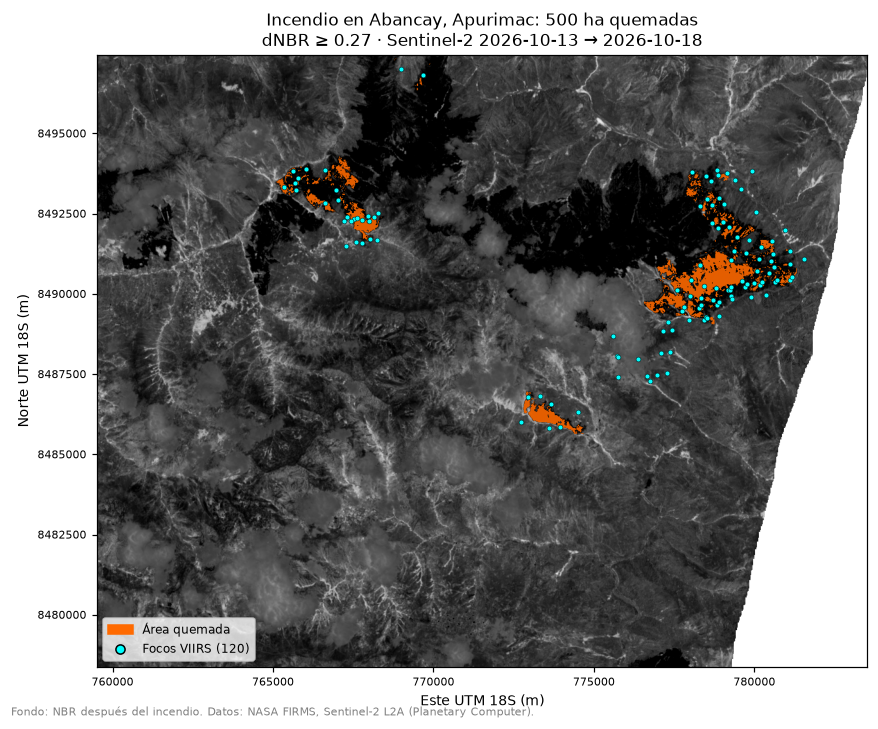

In [8]:
izq, abajo, der, arriba = array_bounds(*dnbr.shape, transform)
extent = (izq, der, abajo, arriba)

fig, ax = plt.subplots(figsize=(8, 6.6))
ax.imshow(nbr["después"], cmap="gray", vmin=-0.2, vmax=0.8, extent=extent)
capa = np.ma.masked_where(~quemado, np.ones(dnbr.shape))
ax.imshow(capa, cmap=ListedColormap(["#ff6a00"]), alpha=0.9, extent=extent)
ax.scatter(focos_utm.geometry.x, focos_utm.geometry.y, s=10, c="cyan", edgecolors="k", linewidths=0.3)
ax.set_title(f"Incendio en {ubicacion}: {ha_quemadas:,.0f} ha quemadas\n"
             f"dNBR ≥ {UMBRAL_DNBR} · Sentinel-2 {escenas['antes'].datetime.date()} → "
             f"{escenas['después'].datetime.date()}", fontsize=11)
ax.set_xlabel("Este UTM 18S (m)")
ax.set_ylabel("Norte UTM 18S (m)")
ax.tick_params(labelsize=7)
ax.ticklabel_format(style="plain")
ax.legend(handles=[Patch(color="#ff6a00", label="Área quemada"),
                   Line2D([], [], marker="o", ls="", mfc="cyan", mec="k", label=f"Focos VIIRS ({len(focos)})")],
          loc="lower left", fontsize=8)
fig.text(0.01, 0.01, "Fondo: NBR después del incendio. Datos: NASA FIRMS, Sentinel-2 L2A (Planetary Computer).",
         fontsize=7, color="gray")
fig.tight_layout()
fig.savefig(SALIDAS / "mapa_area_quemada.png", dpi=150)
plt.show()

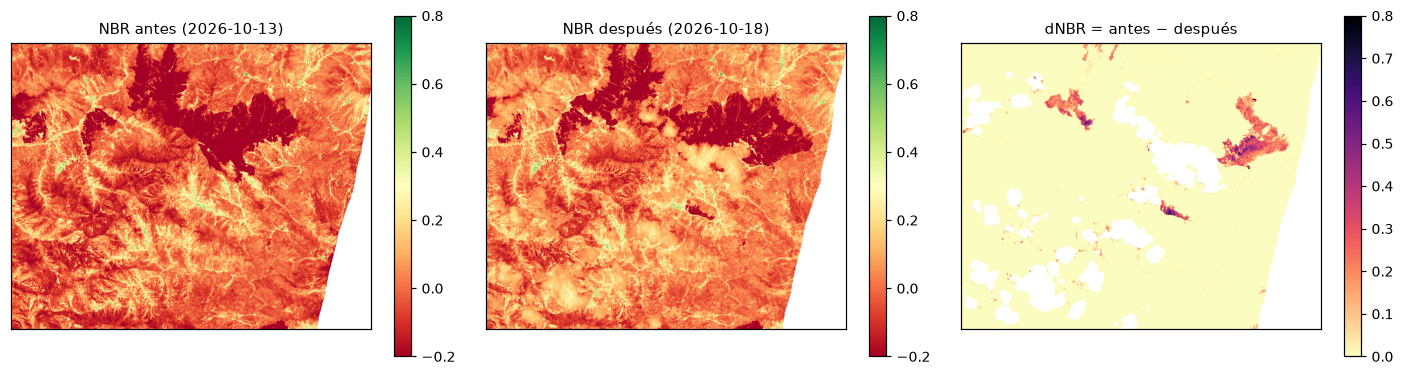

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.4))
paneles = [
    (f"NBR antes ({escenas['antes'].datetime.date()})", nbr["antes"], "RdYlGn", (-0.2, 0.8)),
    (f"NBR después ({escenas['después'].datetime.date()})", nbr["después"], "RdYlGn", (-0.2, 0.8)),
    ("dNBR = antes − después", dnbr, "magma_r", (0, 0.8)),
]
for ax, (titulo, img, cmap, lim) in zip(ejes, paneles):
    im = ax.imshow(img, cmap=cmap, vmin=lim[0], vmax=lim[1], extent=extent)
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.tight_layout()
fig.savefig(SALIDAS / "nbr_antes_despues.png", dpi=130)
plt.show()

## 8 · Tabla resumen y tres hallazgos

Todas las cifras salen del análisis de arriba; no se escribió ninguna a mano.

In [10]:
resumen = pd.DataFrame([{
    "ubicacion": ubicacion,
    "centro_lat": round(centro.y, 4), "centro_lon": round(centro.x, 4),
    "bbox_zona": str(BBOX),
    "fecha_antes": str(escenas["antes"].datetime.date()),
    "nubes_escena_antes_pct": round(escenas["antes"].properties["eo:cloud_cover"], 1),
    "nubes_zona_antes_pct": round(nubes_local["antes"], 1),
    "fecha_despues": str(escenas["después"].datetime.date()),
    "nubes_escena_despues_pct": round(escenas["después"].properties["eo:cloud_cover"], 1),
    "nubes_zona_despues_pct": round(nubes_local["después"], 1),
    "sin_dato_despues_pct": round(sin_dato["después"], 1),
    "n_focos_viirs": len(focos),
    "n_focos_bajo_nubes": n_focos_bajo_nubes,
    "n_focos_despues_de_imagen": n_focos_tras_imagen,
    "pct_focos_verificables_con_cicatriz": round(pct_focos_con_cicatriz),
    "cobertura_principal": principal,
    "cobertura_principal_pct": round(pct_principal),
    "umbral_dnbr": UMBRAL_DNBR,
    "radio_focos_m": RADIO_FOCOS_M,
    "ha_quemadas": round(ha_quemadas),
    "ha_quemadas_sin_filtro_focos": round(ha_sin_filtro),
    "pct_zona_quemada": round(pct_quemado, 1),
    "dnbr_medio_area_quemada": round(dnbr_medio, 3),
}])
resumen.to_csv(SALIDAS / "resumen_incendio.csv", index=False)

print(f"Área quemada estimada: {ha_quemadas:,.0f} ha\n")
print("Tres hallazgos")
print(f"  1. {ha_quemadas:,.0f} ha quemadas ({quemado.sum():,} píxeles de 20 m con dNBR >= {UMBRAL_DNBR})")
print(f"  2. {len(focos)} focos VIIRS en la zona entre el {focos.acq_date.min()} y el {focos.acq_date.max()}")
print(f"  3. {pct_principal:.0f} % del área quemada era {principal.lower()} (WorldCover 2021)")
print(f"\nExtra: {pct_quemado:.1f} % de la zona válida quemada · dNBR medio {dnbr_medio:.2f} · "
      f"{n_focos_bajo_nubes} focos bajo píxeles enmascarados · {n_focos_tras_imagen} focos posteriores a la imagen 'después'")

Área quemada estimada: 500 ha

Tres hallazgos
  1. 500 ha quemadas (12,503 píxeles de 20 m con dNBR >= 0.27)
  2. 120 focos VIIRS en la zona entre el 2026-10-14 y el 2026-10-19
  3. 73 % del área quemada era pastizal (WorldCover 2021)

Extra: 1.4 % de la zona válida quemada · dNBR medio 0.36 · 4 focos bajo píxeles enmascarados · 13 focos posteriores a la imagen 'después'


## Limitaciones

- **Un foco no es un incendio completo.** Es un píxel de 375 m donde VIIRS detectó calor. Los focos posteriores a la
  imagen «después» no tienen su área medida.
- **Las nubes** pueden ocultar fuego o área quemada. Mira cuántos focos caen sobre píxeles enmascarados.
- **El área depende del umbral.** Compara las tres cifras de sensibilidad de la sección 4.
- **La validación solo comprueba una dirección:** que los focos caigan cerca de cicatrices. No mide el error del área.
- **Las fechas importan.** Una imagen posterior más tardía captaría más área, pero la del 20 de octubre estaba casi toda nublada.
- Es una **estimación** basada en imágenes satelitales, no una medición en campo.